In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path

if Path(sys.prefix).name == ".venv-metal":
    os.environ["ENABLE_PJRT_COMPATIBILITY"] = "1"
    os.environ["JAX_PLATFORMS"] = "METAL,cpu"
else:
    os.environ["JAX_PLATFORMS"] = "cpu"

import jax
import matplotlib.pyplot as plt

print("JAX backend:", jax.default_backend(), "| devices:", jax.devices())

if Path.cwd().name == "notebooks":
    %cd ..

JAX backend: cpu | devices: [CpuDevice(id=0)]
/Users/alyaev.roman/Desktop/PhD_Code/drums


In [2]:
from drums.models.flow_matching import main, sample
from itertools import permutations
import numpy as np
import jax
import jax.numpy as jnp
import jax.random as jr

orderings = jnp.array(list(permutations(range(3))))


def procrustes_error(target, prediction):
    target = target - target.mean(axis=0)

    def ordering_error(ordering):
        candidate = prediction[ordering]
        candidate = candidate - candidate.mean(axis=0)
        u, _, vt = jnp.linalg.svd(candidate.T @ target, full_matrices=False)
        aligned = candidate @ (u @ vt)
        return jnp.mean(
            jnp.linalg.norm(target - aligned, axis=1)
            / jnp.linalg.norm(target, axis=1)
        )

    return jnp.min(jax.vmap(ordering_error)(orderings))


# Metal does not support the SVD used by Procrustes alignment.
cpu_device = jax.devices("cpu")[0]
cpu_batch_error = jax.jit(jax.vmap(procrustes_error), backend="cpu")


def batch_error(target, prediction):
    return cpu_batch_error(
        jax.device_put(target, cpu_device),
        jax.device_put(prediction, cpu_device),
    )


def evaluate(model, spectra, vertices, n_draws=4, n_steps=100, seed=123):
    errors = []
    for draw_key in jr.split(jr.PRNGKey(seed), n_draws):
        keys = jr.split(draw_key, len(spectra))
        chunks = []
        for start in range(0, len(spectra), 128):
            stop = start + 128
            predictions = jax.vmap(
                lambda spectrum, key: sample(model, spectrum, key, n_steps=n_steps)
            )(spectra[start:stop], keys[start:stop])
            chunks.append(np.asarray(batch_error(vertices[start:stop], predictions)))
        errors.append(np.concatenate(chunks))
    return np.stack(errors)

/var/folders/vh/_2cy_xz12dlfnn_gfh7ln8840000gn/T/ipykernel_71504/2855823639.py:29: DeprecationWarning: backend and device argument on jit is deprecated. You can use `jax.device_put(..., jax.local_devices(backend="cpu")[0])` on the inputs to the jitted function to get the same behavior.
  cpu_batch_error = jax.jit(jax.vmap(procrustes_error), backend="cpu")


In [3]:
model17, history17, spectra17, vertices17 = main(seed=17, canonical=False, predictor="mlp")

0: train=1.2317, test=1.2315
500: train=0.7322, test=0.5976
1000: train=0.5803, test=0.5527
1500: train=0.6331, test=0.5256
2000: train=0.4860, test=0.4845
2500: train=0.4972, test=0.4854
3000: train=0.4272, test=0.4527
3500: train=0.4888, test=0.4484
4000: train=0.4626, test=0.4405
4500: train=0.4062, test=0.4412


In [4]:
assert spectra17.shape == (1000, 30)
assert vertices17.shape == (1000, 3, 2)
N_DRAWS, N_STEPS = 2, 20

In [5]:
errors17 = evaluate(model17, spectra17, vertices17, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Seed 17:", "train", errors17[:, :900].mean(), "test", errors17[:, 900:].mean())

Seed 17: train 0.154272 test 0.15690418


In [6]:
# Baseline: log + standardise, AdamW, warmup + cosine, clipping, all orderings.
baseline = {17: (0.0054, 0.0058)}
train_error, test_error = errors17[:, :900].mean(), errors17[:, 900:].mean()
b_train, b_test = baseline[17]
print(f"Seed 17: all-orderings Procrustes error; FM averages {N_DRAWS} draws, {N_STEPS} RK4 steps")
print("FM train | FM test | baseline train | baseline test")
print(f"{train_error:.4f}   | {test_error:.4f}  | {b_train:.4f}         | {b_test:.4f}")
print("FM test std across sampling draws:", float(errors17[:, 900:].mean(axis=1).std(ddof=1)))

Seed 17: all-orderings Procrustes error; FM averages 2 draws, 20 RK4 steps
FM train | FM test | baseline train | baseline test
0.1543   | 0.1569  | 0.0054         | 0.0058
FM test std across sampling draws: 0.0008005267009139061


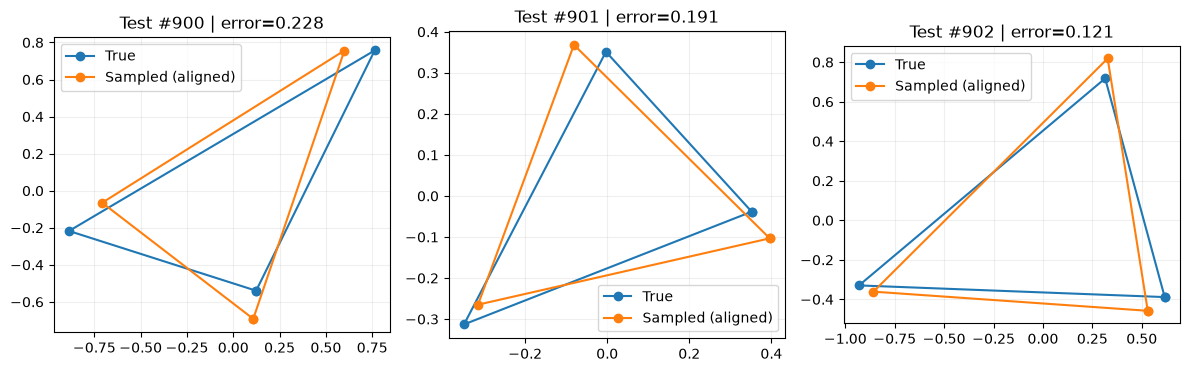

In [7]:
indices = [900, 901, 902]
keys = jr.split(jr.PRNGKey(456), len(indices))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, index, key in zip(axes, indices, keys):
    target = np.asarray(vertices17[index])
    target = target - target.mean(axis=0)
    prediction = np.asarray(sample(model17, spectra17[index], key, n_steps=N_STEPS))

    candidates = prediction[np.asarray(orderings)]
    candidates = candidates - candidates.mean(axis=1, keepdims=True)
    u, _, vt = np.linalg.svd(candidates.transpose(0, 2, 1) @ target)
    aligned = candidates @ (u @ vt)
    errors = np.mean(
        np.linalg.norm(target - aligned, axis=2)
        / np.linalg.norm(target, axis=1), axis=1
    )
    best = np.argmin(errors)

    for triangle, label in [(target, "True"), (aligned[best], "Sampled (aligned)")]:
        closed = np.vstack([triangle, triangle[0]])
        ax.plot(closed[:, 0], closed[:, 1], "o-", label=label)
    ax.set_title(f"Test #{index} | error={errors[best]:.3f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

In [8]:
model_c17, history_c17, spectra_c17, vertices_c17 = main(seed=17, canonical=True, predictor="mlp")
errors_c17 = evaluate(model_c17, spectra_c17, vertices17, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Canonical seed 17:", "train", errors_c17[:, :900].mean(), "test", errors_c17[:, 900:].mean())

0: train=1.2214, test=1.1809
500: train=0.1769, test=0.1158
1000: train=0.0546, test=0.0556
1500: train=0.0819, test=0.0433
2000: train=0.0441, test=0.0416
2500: train=0.0717, test=0.0427
3000: train=0.0317, test=0.0301
3500: train=0.0394, test=0.0271
4000: train=0.0316, test=0.0168
4500: train=0.0311, test=0.0172
Canonical seed 17: train 0.038974617 test 0.03867855


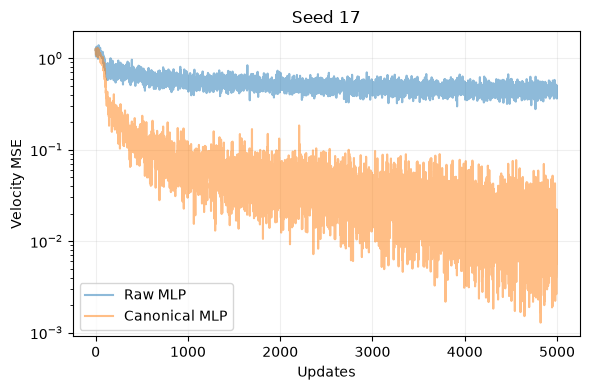

Seed 17: 2 draws per drum, 20 RK4 steps, 900/100 split
model | train error | test error
Raw MLP | 0.1543 | 0.1569
Canonical MLP | 0.0390 | 0.0387
Baseline | 0.0054 | 0.0058


In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history17, alpha=0.5, label="Raw MLP")
ax.plot(history_c17, alpha=0.5, label="Canonical MLP")
ax.set(title="Seed 17", xlabel="Updates", ylabel="Velocity MSE", yscale="log")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Seed 17: {N_DRAWS} draws per drum, {N_STEPS} RK4 steps, 900/100 split")
print("model | train error | test error")
for name, errors in [("Raw MLP", errors17), ("Canonical MLP", errors_c17)]:
    print(f"{name} | {errors[:, :900].mean():.4f} | {errors[:, 900:].mean():.4f}")
print(f"Baseline | {baseline[17][0]:.4f} | {baseline[17][1]:.4f}")

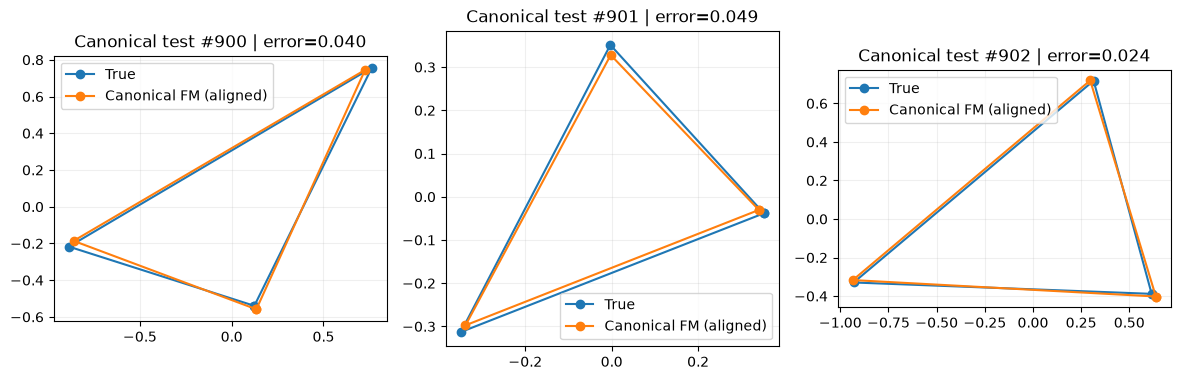

In [10]:
indices = [900, 901, 902]
keys = jr.split(jr.PRNGKey(456), len(indices))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, index, key in zip(axes, indices, keys):
    target = np.asarray(vertices17[index])
    target = target - target.mean(axis=0)
    prediction = np.asarray(sample(model_c17, spectra_c17[index], key, n_steps=N_STEPS))

    candidates = prediction[np.asarray(orderings)]
    candidates = candidates - candidates.mean(axis=1, keepdims=True)
    u, _, vt = np.linalg.svd(candidates.transpose(0, 2, 1) @ target)
    aligned = candidates @ (u @ vt)
    errors = np.mean(
        np.linalg.norm(target - aligned, axis=2)
        / np.linalg.norm(target, axis=1), axis=1
    )
    best = np.argmin(errors)

    for triangle, label in [(target, "True"), (aligned[best], "Canonical FM (aligned)")]:
        closed = np.vstack([triangle, triangle[0]])
        ax.plot(closed[:, 0], closed[:, 1], "o-", label=label)
    ax.set_title(f"Canonical test #{index} | error={errors[best]:.3f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

In [11]:
from importlib import reload
from drums.models import flow_matching

main = reload(flow_matching).main
sample = flow_matching.sample

In [12]:
model_r17, history_r17, spectra_r17, vertices_r17 = main(seed=17, canonical=False, predictor="ring")

0: train=1.5425, test=1.5480
500: train=0.8888, test=0.7971
1000: train=0.8201, test=0.7802
1500: train=0.9598, test=0.7918
2000: train=0.7173, test=0.7654
2500: train=0.8986, test=0.7738
3000: train=0.8129, test=0.7513
3500: train=0.7761, test=0.7608
4000: train=0.7910, test=0.7487
4500: train=0.7410, test=0.7359


In [13]:
errors_r17 = evaluate(model_r17, spectra_r17, vertices_r17, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Ring seed 17:", "train", errors_r17[:, :900].mean(), "test", errors_r17[:, 900:].mean())

Ring seed 17: train 0.1233442 test 0.12507915


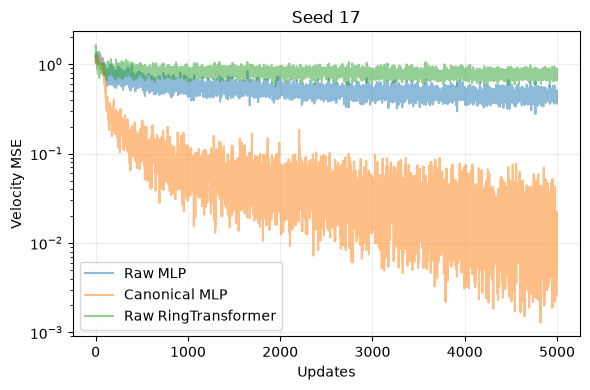

Seed 17: 2 draws per drum, 20 RK4 steps, 900/100 split
model | train error | test error
Raw MLP | 0.1543 | 0.1569
Canonical MLP | 0.0390 | 0.0387
Raw RingTransformer | 0.1233 | 0.1251
Baseline | 0.0054 | 0.0058


In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history17, alpha=0.5, label="Raw MLP")
ax.plot(history_c17, alpha=0.5, label="Canonical MLP")
ax.plot(history_r17, alpha=0.5, label="Raw RingTransformer")
ax.set(title="Seed 17", xlabel="Updates", ylabel="Velocity MSE", yscale="log")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Seed 17: {N_DRAWS} draws per drum, {N_STEPS} RK4 steps, 900/100 split")
print("model | train error | test error")
for name, errors in [
    ("Raw MLP", errors17),
    ("Canonical MLP", errors_c17),
    ("Raw RingTransformer", errors_r17),
]:
    print(f"{name} | {errors[:, :900].mean():.4f} | {errors[:, 900:].mean():.4f}")
print(f"Baseline | {baseline[17][0]:.4f} | {baseline[17][1]:.4f}")

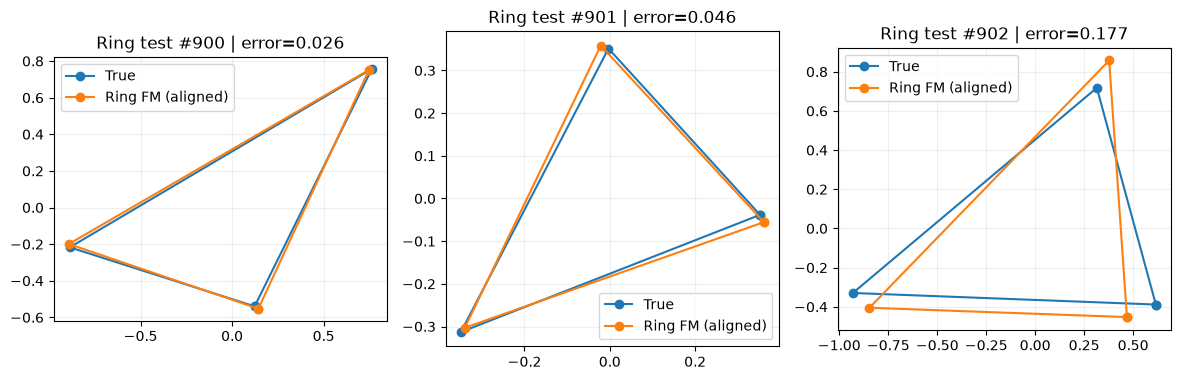

In [15]:
indices = [900, 901, 902]
keys = jr.split(jr.PRNGKey(456), len(indices))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, index, key in zip(axes, indices, keys):
    target = np.asarray(vertices_r17[index])
    target = target - target.mean(axis=0)
    prediction = np.asarray(sample(model_r17, spectra_r17[index], key, n_steps=N_STEPS))

    candidates = prediction[np.asarray(orderings)]
    candidates = candidates - candidates.mean(axis=1, keepdims=True)
    u, _, vt = np.linalg.svd(candidates.transpose(0, 2, 1) @ target)
    aligned = candidates @ (u @ vt)
    errors = np.mean(
        np.linalg.norm(target - aligned, axis=2)
        / np.linalg.norm(target, axis=1), axis=1
    )
    best = np.argmin(errors)

    for triangle, label in [(target, "True"), (aligned[best], "Ring FM (aligned)")]:
        closed = np.vstack([triangle, triangle[0]])
        ax.plot(closed[:, 0], closed[:, 1], "o-", label=label)
    ax.set_title(f"Ring test #{index} | error={errors[best]:.3f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

In [22]:
import pandas as pd
from IPython.display import display

n_train = int(0.9 * errors_r17.shape[1])
test_errors = pd.DataFrame(
    {"mean_error": np.asarray(errors_r17)[:, n_train:].mean(axis=0)},
    index=pd.Index(np.arange(n_train, errors_r17.shape[1]), name="triangle_index"),
)

display(test_errors.describe().T)

,count,mean,std,min,25%,50%,75%,max
mean_error,100.0,0.125079,0.077743,0.022531,0.063822,0.106054,0.159964,0.327045
